
# <center>Customer Segmentation</center>
___

## 1. Library Import


In [26]:
import sys
sys.path.append("..")

In [27]:
import os
import pandas as pd
import numpy as np
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import datetime
from pathlib import Path

In [28]:
path = "../data/sample/"
output_dir = Path("../charts_and_figures")
output_dir.mkdir(exist_ok=True)
sns.set_style("darkgrid")

In [29]:
from src.data import load_raw_tables

customers_df, products_df, sales_df = load_raw_tables(str(path))

## 2. Data Assessment
Bases iniciais serão tratadas e consolidadas na base que será utilizada na segmentação

In [30]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129032 entries, 0 to 129031
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   SALE_ID        129032 non-null  int64 
 1   SALE_DATE      129032 non-null  object
 2   CUSTOMER_ID    129032 non-null  int64 
 3   PRODUCT_ID     129032 non-null  int64 
 4   QUANTITY       129032 non-null  Int64 
 5   SALE_CATEGORY  129032 non-null  string
 6   BRANCH         129032 non-null  int64 
dtypes: Int64(1), int64(4), object(1), string(1)
memory usage: 7.0+ MB


In [31]:
sales_df['SALE_DATE'] = pd.to_datetime(sales_df['SALE_DATE'], format='%Y/%m/%d', errors='coerce')
sales_df['yemo'] = sales_df['SALE_DATE'].apply(lambda x: datetime.date(x.year, x.month, 1))

sales_df = pd.merge(sales_df,products_df,how='left',on=['PRODUCT_ID'])

In [32]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129032 entries, 0 to 129031
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   SALE_ID        129032 non-null  int64         
 1   SALE_DATE      129032 non-null  datetime64[ns]
 2   CUSTOMER_ID    129032 non-null  int64         
 3   PRODUCT_ID     129032 non-null  int64         
 4   QUANTITY       129032 non-null  Int64         
 5   SALE_CATEGORY  129032 non-null  string        
 6   BRANCH         129032 non-null  int64         
 7   yemo           129032 non-null  object        
 8   UNIT           129032 non-null  object        
 9   LEVEL_1        110190 non-null  object        
 10  LEVEL_2        110190 non-null  object        
 11  LEVEL_3        110190 non-null  object        
 12  LEVEL_4        97727 non-null   object        
dtypes: Int64(1), datetime64[ns](1), int64(4), object(6), string(1)
memory usage: 12.9+ MB


### 2.1 Consolidação da Base Transacional


In [33]:
# Agrupando por Dia
day_sales         = sales_df.groupby(['SALE_DATE','yemo','CUSTOMER_ID']).agg({'QUANTITY':['sum','count']}).reset_index()
day_sales.columns = day_sales.columns.droplevel(0)
day_sales.columns = ['SALE_DATE','yemo','CUSTOMER_ID','quantity','n_prod']

In [34]:
# Agrupando por Mes
month_sales = day_sales.groupby(['yemo','CUSTOMER_ID']).agg({'quantity':['sum','count'],'n_prod':['mean']}).reset_index()
month_sales.columns = month_sales.columns.droplevel(0)
month_sales.columns = ['yemo','CUSTOMER_ID','quantity','freq_int_mes','n_prod']

In [35]:
# Agrupando por Cliente
customer_sales = month_sales.groupby(['CUSTOMER_ID']).agg({'yemo':['max','min'],
                                                       'quantity':['sum'],
                                                       'n_prod':['mean'],
                                                       'freq_int_mes':['sum','mean','count']}).reset_index()

customer_sales.columns = customer_sales.columns.droplevel(0)
customer_sales.columns = ['CUSTOMER_ID','last_purchase','first_purchase','quantity','n_prod','n_pur','mon_freq','n_mon']

In [36]:
# Calculo de variáveis
customer_sales['today'] = datetime.date(2026,8,17)

customer_sales['recency']      = customer_sales.apply(lambda x: (x['today'].year    - x['last_purchase'].year) * 12   + (x['today'].month    - x['last_purchase'].month ),axis=1)
customer_sales['time_relation'] = customer_sales.apply(lambda x: (x['last_purchase'].year - x['first_purchase'].year) * 12 + (x['last_purchase'].month - x['first_purchase'].month ),axis=1)
customer_sales['retention'] = customer_sales.apply(lambda x: (x['today'].year    - x['first_purchase'].year) * 12 + (x['today'].month    - x['first_purchase'].month ),axis=1)

### 2.2 Calculo do share por canal

In [37]:
# Consolidação por Loja
store_sale = sales_df.groupby(['CUSTOMER_ID', 'SALE_CATEGORY'], as_index=False).agg(
    qnty=('QUANTITY', 'sum'),
    n_pur=('SALE_DATE', 'count')  # Conta o número de compras/registros
)

In [38]:
store_sale.head()

,CUSTOMER_ID,SALE_CATEGORY,qnty,n_pur
0,1,STORE,8,6
1,2,STORE,29,24
2,3,STORE,17,17
3,4,STORE,9,5
4,5,CLINIC,5,5


In [39]:
# 1. Initial grouby - building base
store_sale = sales_df.groupby(['CUSTOMER_ID', 'SALE_CATEGORY'], as_index=False).agg(
    qnty=('QUANTITY', 'sum'),
    n_pur=('SALE_DATE', 'nunique')) 

# 2. Removing spaces from SALE_CATEGORY
store_sale['SALE_CATEGORY'] = store_sale['SALE_CATEGORY'].str.strip()

# 3. Mapping SALE_CATEGORY to new column names
category_map = {
    'CLINIC': 'clinic_npur',
    'GROOMING': 'grooming_npur',
    'STORE': 'store_npur',
    'DIGITAL': 'dig_npur',
    'E-COMMERCE': 'ecomm_npur',
}

# 4. Pivoting the DataFrame to have SALE_CATEGORY as columns
store_sale = (
    sales_df
    .assign(SALE_CATEGORY=lambda df: df['SALE_CATEGORY'].str.strip())
    .pivot_table(
        index='CUSTOMER_ID',
        columns='SALE_CATEGORY',
        values='SALE_DATE',
        aggfunc='nunique',
        fill_value=0
    )
    .reset_index()
    .rename(columns=category_map)
)
store_sale.columns.name = None

# 5. Final adjustment of headers and renaming
store_sale.columns.name = None
store_sale = store_sale.rename(columns=category_map)

In [40]:
# Share of purchases by category
category_cols = [col for col in category_map.values() if col in store_sale.columns]
total_purchases = store_sale[category_cols].sum(axis=1)

In [41]:
store_sale_share = store_sale.copy()
store_sale_share[category_cols] = (
    store_sale_share[category_cols]
    .div(total_purchases, axis=0)
    .fillna(0)
)

### 2.3 Unificação da Base e ajustes finais

Descrição das variáveis construídas

*   **last_purchase:** Most recent purchase date
*   **first_purchase:** First purchase date
*   **quantity:** Total quantity of items purchased
*   **n_prod:** Average number of products per purchase
*   **n_pur:** Total number of customer purchases (at most one per day)
*   **mon_freq:** Average monthly purchase frequency
*   **n_mon:** Number of months with purchases
*   **recency:** Months since the most recent purchase
*   **time_relation:** Months between the first and most recent purchase
*   **retention:** Months since the first purchase
*   **clinic_npur:** Share of purchases made at clinics
*   **grooming_npur:** Share of purchases made through grooming services
*   **store_npur:** Share of purchases made in stores
*   **dig_npur:** Share of purchases made through digital marketplaces
*   **ecomm_npur:** Share of purchases made through e-commerce
*   **qnty_pur:** Average quantity of items per purchase


In [42]:
# Unificação
final_df = pd.merge(customer_sales,store_sale_share,how='left',on=['CUSTOMER_ID'])

In [43]:
# Ajuste dos Campos
final_df['qnty_pur'] = final_df['quantity']/final_df['n_pur']
final_df = final_df.drop(['today'],axis=1)

In [44]:
final_df.head()

,CUSTOMER_ID,last_purchase,first_purchase,quantity,n_prod,n_pur,mon_freq,n_mon,recency,time_relation,retention,clinic_npur,dig_npur,ecomm_npur,grooming_npur,store_npur,qnty_pur
0,1,2021-07-01,2020-01-01,8,1.5,4,1.0,4,61,18,79,0,0,0,0,4,2.0
1,2,2021-07-01,2020-02-01,29,2.25,11,1.1,10,61,17,78,0,0,0,0,11,2.636364
2,3,2021-05-01,2020-05-01,17,1.761905,9,1.285714,7,63,12,75,0,0,0,0,9,1.888889
3,4,2021-02-01,2020-11-01,9,2.5,2,1.0,2,66,3,69,0,0,0,0,2,4.5
4,5,2021-06-01,2020-02-01,25,2.214286,10,1.428571,7,62,16,78,2,0,0,1,7,2.5


## 3. Análise das Variáveis

Nesta etapa, as variaveis criadas serão analisadas

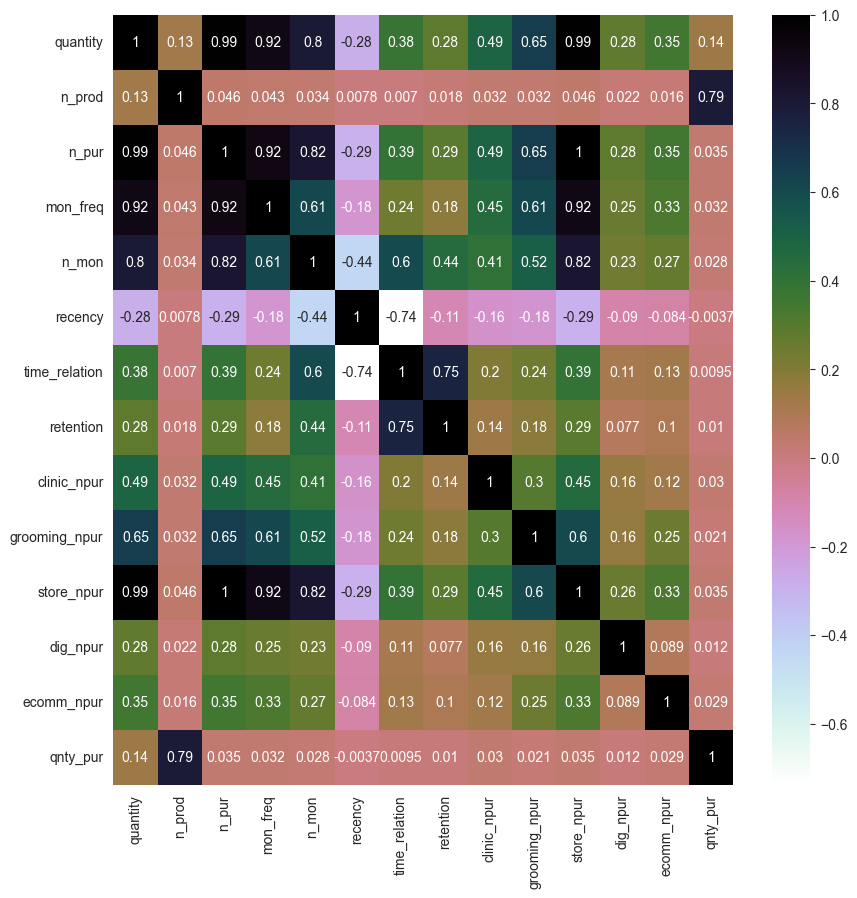

In [45]:
# Avaliação da Correlação entre as variáveis
plt.figure(figsize=(10,10))
sns.heatmap(final_df[['quantity', 'n_prod','n_pur', 'mon_freq', 'n_mon', 'recency',
       'time_relation', 'retention', 'clinic_npur','grooming_npur',
       'store_npur','dig_npur', 'ecomm_npur','qnty_pur']].corr(),annot=True,cmap='cubehelix_r')

plt.show()

In [46]:
#analyzed_variable = 'quantity'
#analyzed_variable = 'n_prod'
#analyzed_variable = 'n_pur'
#analyzed_variable = 'mon_freq'
#analyzed_variable = 'n_mon'
analyzed_variable = 'recency'
#analyzed_variable = 'time_relation'
#analyzed_variable = 'retention'
#analyzed_variable = 'clinic_npur'
#analyzed_variable = 'grooming_npur'
#analyzed_variable = 'store_npur'
#analyzed_variable = 'dig_npur'
#analyzed_variable = 'ecomm_npur'
#analyzed_variable = 'qnty_pur'

fig = px.box(final_df, x=analyzed_variable)
fig.update_traces(orientation='h')
fig.update_layout(
    xaxis={'title': analyzed_variable},
    yaxis={'title': analyzed_variable, 'showline': False, 'ticks': ''}
)
fig.show()

NameError: name 'base_final' is not defined

## 4. Clusterização

Etapa em que será realizada a clusterização

### 4.1 Seleção das Variáveis

In [ ]:
# Base de customers simplificada [Variáveis utilizadas na clusterização, experimente clusterizar com diferentes variáveis]
customers = final_df[['CUSTOMER_ID','n_prod','qnty_pur','mon_freq', 'n_mon', 'recency','store_npur']]

### 4.2 Normalização das Variáveis

In [ ]:
# Base utilizada para clusterização

df_cluster = customers.drop(['CUSTOMER_ID'],axis=1)

# Normalização das variáveis
std_data = StandardScaler().fit_transform(df_cluster)
df_cluster = pd.DataFrame(data=std_data, columns=df_cluster.columns, index=df_cluster.index)

df_cluster.describe()

,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp
count,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04
mean,4.508058e-16,1.027037e-15,-5.626742e-16,7.613733e-14,-1.421572e-14,3.073644e-16
std,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00
min,-7.264561e-01,-3.012111e-01,-5.153730e-01,-7.168529e-01,-9.298197e-01,-1.798485e+00
25%,-7.264561e-01,-2.835752e-01,-5.153730e-01,-7.168529e-01,-7.312844e-01,-7.129298e-01
50%,-2.452758e-01,-2.707130e-01,-5.153730e-01,-4.121187e-01,-3.342138e-01,7.344764e-01
75%,2.760028e-01,-4.108010e-02,1.640278e-01,1.973497e-01,6.584626e-01,7.344764e-01
max,2.513698e+01,1.592018e+02,3.413407e+01,5.682566e+00,3.239422e+00,7.344764e-01


### 4.3 Definição do número de clusters

In [ ]:
# Cálculo das iterações do k-means (Cotovelo)

wcss = {}
for k in range(1, 26):
  print(k)
  kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=200, random_state=3)
  kmeans.fit(df_cluster)
  wcss[k] = kmeans.inertia_

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25


In [ ]:
fig = make_subplots(
    rows=1,
    cols=1,
    subplot_titles=['Método do Cotovelo'],
    shared_xaxes=True,
    shared_yaxes=False)


fig.add_trace(
    go.Scatter(
        x=list(wcss.keys()),
        y=list(wcss.values()),
        mode='lines+markers',
        textposition='top center',
        showlegend=False),
    row=1,
    col=1)

fig.update_xaxes(visible=True, title='No. of clusters',row=1, col=1)
fig.update_yaxes(visible=True, title='Cluster Inertia',row=1, col=1)

fig.update_layout(
  title='Definição do Nº Ideal de Clusters',
  showlegend=False,
  xaxis_showticklabels=True,
  height=400,
  width=800,
  xaxis = dict(
    tickmode = 'linear',
    tick0 = 0,
    dtick = 1))

fig.show()

### 4.4 Clusterização não Hierárquica (K-Means)

In [ ]:
# Definição do DF a ser Clusterizado
df_cluster_km = df_cluster.copy()

# Clusterização
clus = KMeans(n_clusters=5, init='k-means++', max_iter=300,random_state=3)
clus.fit(df_cluster_km)

# Ajustando as colunas
df_cluster_km.loc[:, 'CLUSTER'] = clus.labels_
df_cluster_km.head()

,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp,CLUSTER
0,0.947093,0.672688,1.975763,4.463629,-0.929820,-0.329367,4
1,-0.726456,-0.283271,-0.515373,-0.716853,-0.731284,-1.798485,1
2,-0.425718,0.168819,-0.515373,-0.412119,-0.929820,-0.954164,1
3,2.882396,-0.238421,-0.515373,-0.716853,-0.731284,0.734476,0
4,0.626863,0.272647,5.599234,-0.412119,-0.929820,-0.672724,4


In [ ]:
# Inserção do cluster na base de customers
customers = pd.concat([customers, df_cluster_km[['CLUSTER']]], axis=1)

## 5. Análise Clusters
Entender as principais características dos clusters

### 5.1 Volumetria

In [ ]:
cluster_size = customers.groupby('CLUSTER', as_index=False)['CUSTOMER_ID'].count()
fig = px.bar(cluster_size, x="CLUSTER", y="CUSTOMER_ID", title="# Clientes por Cluster")
fig.update_layout(
    width=600,
    height=400,
    showlegend=False)
fig.show()

### 5.2 Boxplot

In [ ]:
# Variáveis utilizadas na clusterização
cluster_variables = customers.set_index(['CUSTOMER_ID', 'CLUSTER']).columns.tolist()
print(f'Variáveis: {cluster_variables}')

Variáveis: ['n_prod', 'qntd_compra', 'freq_mes', 'n_meses', 'recencia', 'loja_ncomp']


In [ ]:
# Analise do comportamento de uma variavel em função do Cluster

for cluster_variable in cluster_variables:
  fig = px.box(customers, x=cluster_variable, y='CLUSTER', points=False)
  fig.update_traces(orientation='h')
  fig.update_layout(
      title=f'Distribuição da {cluster_variable} por Cluster',
      xaxis={'title': cluster_variable},
      yaxis={'title': 'Cluster', 'showline': False, 'ticks': ''}
  )

  fig.update_layout(
      width=800,
      height=400,
      showlegend=False)

  fig.show()

### 5.3 Coordenadas Paralelas

In [ ]:
customers = pd.merge(customers,final_df[['CUSTOMER_ID',
                                         'grooming_npur','clinic_npur','dig_npur', 'ecomm_npur','quantity','n_pur'
                                         ]],how='left',on=['CUSTOMER_ID'])

In [ ]:
cluster_means = customers.groupby(['CLUSTER']).mean().reset_index()
cluster_means.head()

,CLUSTER,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp,estetica_ncomp,clinica_ncomp,dig_ncomp,ecomm_ncomp,qntd,n_compras
0,0,6.800910,15.881712,1.121579,1.936462,4.884446,0.936741,0.017101,0.017356,0.014448,0.014354,38.064622,2.245171
1,1,1.348606,101.702193,1.141398,1.964234,6.391829,0.075324,0.392819,0.246601,0.132333,0.152923,289.107802,2.323789
2,2,1.960759,4.820878,1.090820,1.480966,10.898916,0.973210,0.018111,0.007354,0.000000,0.001324,11.135931,1.645867
3,3,2.068996,8.022790,1.164468,3.158401,2.052639,0.919141,0.036983,0.015110,0.010372,0.018394,36.201434,3.723460
4,4,2.126173,42.088795,1.969341,9.363971,1.088720,0.690735,0.202749,0.078433,0.011274,0.016809,782.412968,17.680184


In [ ]:
parallel_variables = ['n_prod','qnty_pur', 'mon_freq', 'n_mon','recency', 'store_npur']

In [ ]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(cluster_means[parallel_variables +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

In [ ]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(cluster_means[parallel_variables +['grooming_npur','clinic_npur','dig_npur', 'ecomm_npur','quantity','n_pur'] +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

### 5.4 Conclusões

Leitura dos Clusters

**Cluster 0:**
*   Menor número de Clientes (5,9k)
*   Alto número de itens consumidos por compra
*   Baixa quantidade por compra (alta diversidade mas baixa quantidade)
*   Alta presença nas Lojas
*   Baixa quantidade total

**Cluster 1:**
*   2º maior cluster (20% dos clientes)
*   Baixo número de itens por compra
*   Elevada quantidade por compra
*   Baixa frequência mensal
*   Baixa fidelidade (alta recencia, baixo nº meses)
*   Baixa presença nas lojas, porém alta presença em Estética e Clínicas (maior foco em serviços)
*   Alta quantidade de produtos médio por cliente

**Cluster 2:**
*   Baixa quantidade de itens por compra
*   Baixa frequencia mensal
*   Baixo nº meses
*   Alta recencia
*   Alta presença em lojas
*   Clientes com baixo engajamento (compram 1 vez e não voltam mais)

**Cluster 3:**
*   Maior cluster de clientes (35k)
*   Baixo nº de itens por compra
*   Baixa quantidade por compra
*   Bom engajamento (Baixa Recencia e alto nº meses)
*   Alta presença em lojas

**Cluster 4:**
*   Alta quantidade por compra
*   Alta frequencia por mes
*   Alto nº de meses
*   Baixa recencia
*   Presença em Lojas, Estética e Clinicas
*   Cluster dos clientes mais rentáveis
